In [1]:
print("Weather Data Trend Analysis and Simple Forecasting")
print("Project: AI & ML Capstone 18 ")
print("Location: Chennai")
print("Let's start our project!")

Weather Data Trend Analysis and Simple Forecasting
Project: AI & ML Capstone 18 
Location: Chennai
Let's start our project!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
import requests
import pandas as pd

# Chennai location
latitude = 13.0827
longtitude = 80.2707

#Download historical weather data
url = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
    "?parameters=T2M,RH2M,PRECTOTCORR"
    "&community=RE"
    f"&longitude={longtitude}"
    f"&latitude={latitude}"
    "&start=20250101"
    "&end=20251231"
    "&format=JSON"
)

response = requests.get(url,timeout=60)

print("Status Code:",response.status_code)

data = response.json()

print("Weather data downloaded successfully!")

Status Code: 200
Weather data downloaded successfully!


In [4]:
weather = data["properties"]["parameter"]

df = pd.DataFrame({
    "Date": pd.to_datetime(
        list(weather["T2M"].keys()),
        format="%Y%m%d"
    ),
    "Temperature_C": list(weather["T2M"].values()),
    "Humitidity_Percent": list(weather["RH2M"].values()),
    "Rainfall_mm": list(weather["PRECTOTCORR"].values())
})

print("First 10 Weather Records:")
display(df.head(10))

print("\nDataset Information:")
print(df.info())

First 10 Weather Records:


,Date,Temperature_C,Humitidity_Percent,Rainfall_mm
0,2025-01-01,24.48,83.31,0.00
1,2025-01-02,24.06,82.63,0.03
2,2025-01-03,23.63,79.01,0.01
3,2025-01-04,23.48,77.78,0.02
4,2025-01-05,23.74,76.19,0.00
5,2025-01-06,24.22,71.06,0.00
6,2025-01-07,23.66,76.78,0.00
7,2025-01-08,23.06,76.70,0.00
8,2025-01-09,23.51,78.76,0.05
9,2025-01-10,24.06,82.27,0.13



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                365 non-null    datetime64[ns]
 1   Temperature_C       365 non-null    float64       
 2   Humitidity_Percent  365 non-null    float64       
 3   Rainfall_mm         365 non-null    float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 11.5 KB
None


In [5]:
# Check for missing values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates(subset="Date")

# Remove impossible values
df.loc[~df["Temperature_C"].between(-5, 55), "Temperature_C"] = np.nan
df.loc[~df["Humitidity_Percent"].between(0, 100), "Humitidity_Percent"] = np.nan
df.loc[~df["Rainfall_mm"].between(0, 1000), "Rainfall_mm"] = np.nan

# Fill missing values
df[["Temperature_C", "Humitidity_Percent", "Rainfall_mm"]] = (
    df[["Temperature_C", "Humitidity_Percent", "Rainfall_mm"]]
    .interpolate(limit=3)
)

# Remove remaining missing values
df = df.dropna()

print("\nWeather Data Cleaned Successfully!")
print("Total Records:", len(df))

display(df.head())

Missing Values Before Cleaning:
Date                  0
Temperature_C         0
Humitidity_Percent    0
Rainfall_mm           0
dtype: int64

Weather Data Cleaned Successfully!
Total Records: 365


,Date,Temperature_C,Humitidity_Percent,Rainfall_mm
0,2025-01-01,24.48,83.31,0.00
1,2025-01-02,24.06,82.63,0.03
2,2025-01-03,23.63,79.01,0.01
3,2025-01-04,23.48,77.78,0.02
4,2025-01-05,23.74,76.19,0.00


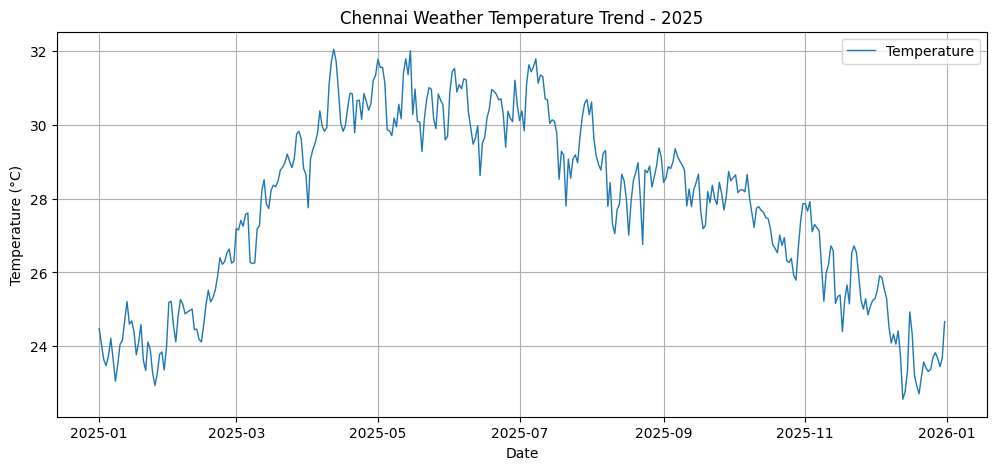

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Temperature_C"],
    label="Temperature",
    linewidth=1
)

plt.title("Chennai Weather Temperature Trend - 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)

plt.show()

In [7]:
# Monthly Weather Analysis

df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month

monthly_weather = df.groupby("Month")[
    ["Temperature_C", "Humitidity_Percent", "Rainfall_mm"]
].mean()

print("Monthly Weather Analysis:")
display(monthly_weather.round(2))

Monthly Weather Analysis:


,Temperature_C,Humitidity_Percent,Rainfall_mm
Month,,,
1,23.96,80.47,1.45
2,25.28,74.87,0.00
3,28.14,70.32,0.47
4,30.37,67.22,1.16
5,30.57,68.43,3.11
6,30.43,65.86,1.86
7,30.13,65.18,3.47
8,28.49,76.00,5.80
9,28.33,78.70,5.28


In [18]:

import pandas as pd

if "df" in globals() and {"Date", "Temperature_C"}.issubset(df.columns):
    data = df.copy()
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    data["Temperature_C"] = pd.to_numeric(
        data["Temperature_C"], errors="coerce"
    )
    data = data.dropna(subset=["Date", "Temperature_C"])

    if not data.empty:
        latest = data.loc[data["Date"].idxmax()]
        print("Latest Date:", latest["Date"].strftime("%Y-%m-%d"))
        print("Latest Temperature:", latest["Temperature_C"], "°C")
    else:
        print("No valid date and temperature records found.")
else:
    print("Dataset not loaded. Run the data-loading cells first.")


Latest Date: 2025-12-31
Latest Temperature: 24.67 °C


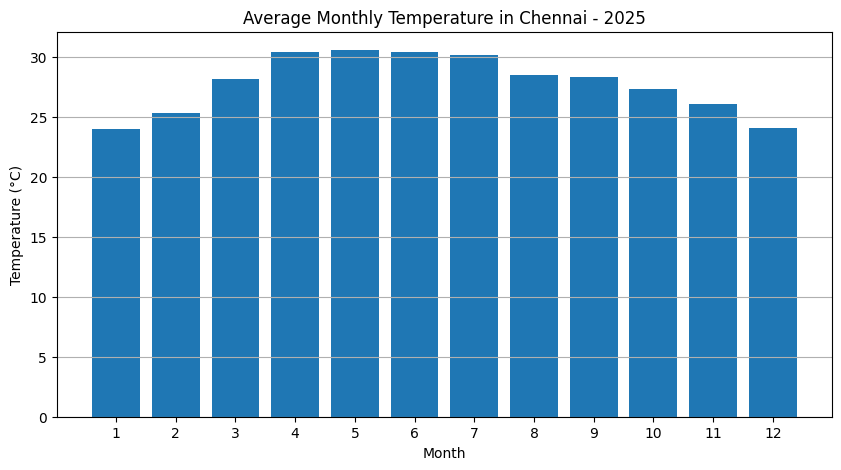

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_weather.index,
    monthly_weather["Temperature_C"]
)

plt.title("Average Monthly Temperature in Chennai - 2025")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(axis="y")

plt.show()

In [9]:
# Step 9: Prepare Data for Machine Learning

import pandas as pd
import numpy as np

# Create date-based features
df["Date"] = pd.to_datetime(df["Date"])

df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

# Select input and output
X = df[["Day", "Month", "Year"]]
y = df["Temperature_C"]

print("Input Data:")
display(X.head())

print("Target Temperature:")
display(y.head())

print("Total Records:", len(df))

Input Data:


,Day,Month,Year
0,1,1,2025
1,2,1,2025
2,3,1,2025
3,4,1,2025
4,5,1,2025


Target Temperature:


,Temperature_C
0,24.48
1,24.06
2,23.63
3,23.48
4,23.74


Total Records: 365


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Split the data chronologically
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict temperature
y_pred = model.predict(X_test)

print("Model Training Completed Successfully!")
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

Model Training Completed Successfully!
Mean Absolute Error: 2.31
R2 Score: -2.53


   Actual Temperature  Predicted Temperature
0               26.53                27.0992
1               27.01                27.0779
2               26.73                27.1355
3               26.94                27.0962
4               26.32                27.2230
5               26.27                27.4582
6               26.38                27.4094
7               25.93                27.2819
8               25.79                27.4667
9               26.66                27.8386


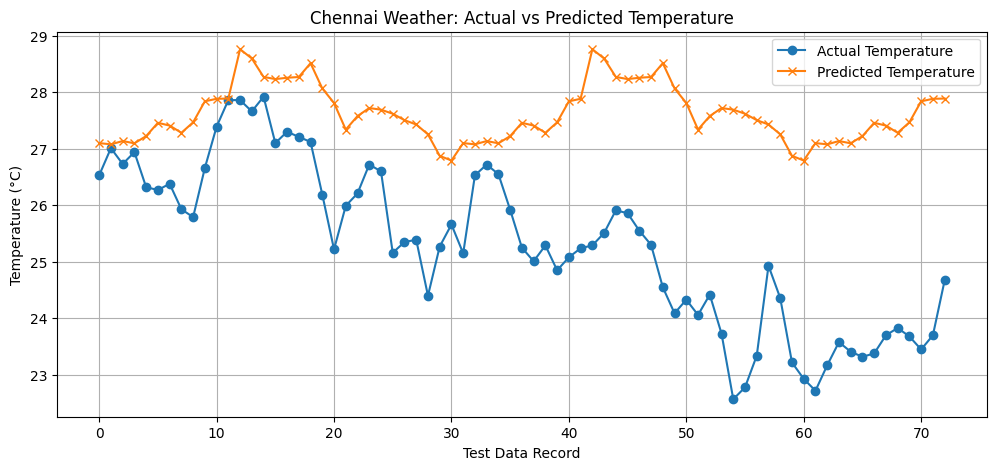

In [11]:

import matplotlib.pyplot as plt
import pandas as pd

# Compare actual and predicted temperatures
comparison = pd.DataFrame({
    "Actual Temperature": y_test.values,
    "Predicted Temperature": y_pred
})

print(comparison.head(10))

plt.figure(figsize=(12, 5))
plt.plot(
    comparison["Actual Temperature"].values,
    label="Actual Temperature",
    marker="o"
)
plt.plot(
    comparison["Predicted Temperature"].values,
    label="Predicted Temperature",
    marker="x"
)

plt.title("Chennai Weather: Actual vs Predicted Temperature")
plt.xlabel("Test Data Record")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()


In [12]:

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Prepare daily temperature data
weather = df.copy()
weather["Date"] = pd.to_datetime(weather["Date"])
weather = weather.sort_values("Date").drop_duplicates("Date")
weather = weather.set_index("Date")

# Ensure daily frequency; missing days remain missing
weather = weather[["Temperature_C"]].asfreq("D")

# Create calendar and past-temperature features
weather["Month"] = weather.index.month
weather["DayOfYear"] = weather.index.dayofyear
weather["Year"] = weather.index.year

weather["Lag_1"] = weather["Temperature_C"].shift(1)
weather["Lag_7"] = weather["Temperature_C"].shift(7)
weather["Lag_14"] = weather["Temperature_C"].shift(14)
weather["Lag_30"] = weather["Temperature_C"].shift(30)

weather["Rolling_7"] = (
    weather["Temperature_C"].shift(1).rolling(7).mean()
)
weather["Rolling_30"] = (
    weather["Temperature_C"].shift(1).rolling(30).mean()
)

# Remove rows without sufficient past data or target
weather = weather.dropna()

features = [
    "Month", "DayOfYear", "Year",
    "Lag_1", "Lag_7", "Lag_14", "Lag_30",
    "Rolling_7", "Rolling_30"
]

X = weather[features]
y = weather["Temperature_C"]

# Chronological split: earlier dates train, later dates test
split = int(len(weather) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

model_improved = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42
)

model_improved.fit(X_train, y_train)
predictions = model_improved.predict(X_test)

print("Improved Model Results")
print("MAE:", round(mean_absolute_error(y_test, predictions), 2), "°C")
print("R²:", round(r2_score(y_test, predictions), 2))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Improved Model Results
MAE: 1.1 °C
R²: 0.09
Training records: 268
Testing records: 67


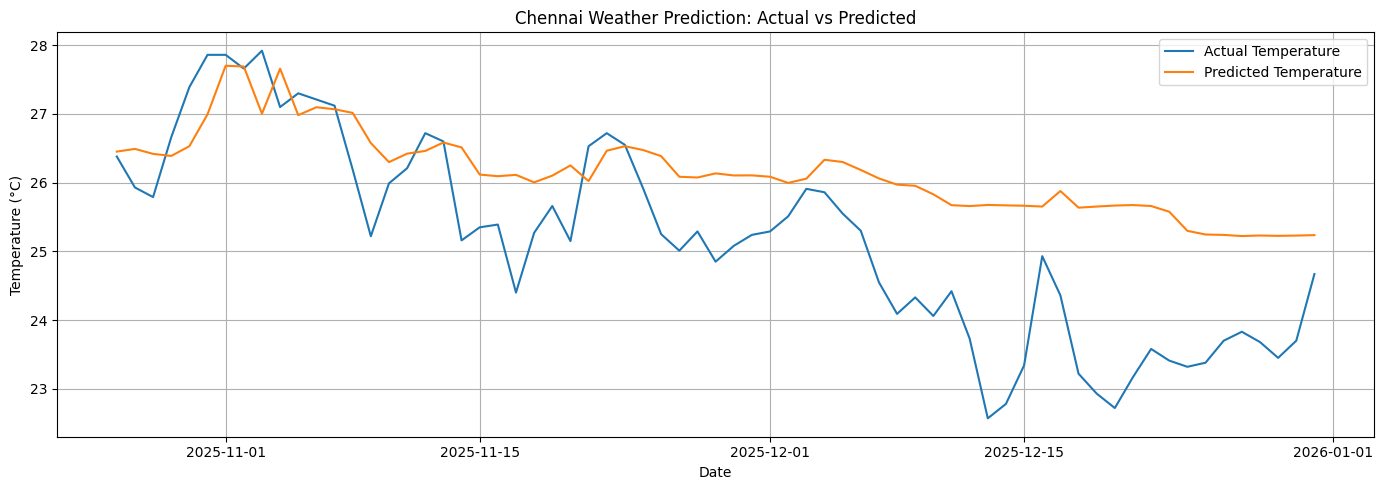

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Temperature"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Temperature"
)

plt.title("Chennai Weather Prediction: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("CHENNAI WEATHER PREDICTION - MODEL EVALUATION")
print("---------------------------------------------")
print(f"MAE  : {mae:.2f} °C")
print(f"RMSE : {rmse:.2f} °C")
print(f"R²   : {r2:.2f}")


CHENNAI WEATHER PREDICTION - MODEL EVALUATION
---------------------------------------------
MAE  : 1.10 °C
RMSE : 1.36 °C
R²   : 0.09


In [15]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Compare on exactly the same test dates
actual = y_test

# Persistence baseline: use the previous day's temperature
previous_day = weather["Temperature_C"].shift(1).reindex(actual.index)

# Seasonal baseline: use the temperature from 7 days earlier
previous_week = weather["Temperature_C"].shift(7).reindex(actual.index)

def evaluate(name, actual, predicted):
    valid = actual.notna() & predicted.notna()
    a = actual[valid]
    p = predicted[valid]

    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(a, p), 2), "°C")
    print("RMSE:", round(np.sqrt(mean_squared_error(a, p)), 2), "°C")
    print("R²:", round(r2_score(a, p), 2))

evaluate("Improved Random Forest", actual,
         pd.Series(predictions, index=actual.index))
evaluate("Previous-day baseline", actual, previous_day)
evaluate("Previous-week baseline", actual, previous_week)



Improved Random Forest
MAE: 1.1 °C
RMSE: 1.36 °C
R²: 0.09

Previous-day baseline
MAE: 0.44 °C
RMSE: 0.58 °C
R²: 0.84

Previous-week baseline
MAE: 0.99 °C
RMSE: 1.17 °C
R²: 0.33


In [16]:

# Step 17: Chennai Next-Day Temperature Prediction

import pandas as pd
import matplotlib.pyplot as plt

# Get the latest available temperature
latest_date = df["Date"].max()
latest_temperature = df.loc[
    df["Date"] == latest_date, "Temperature_C"
].iloc[-1]

# Persistence baseline: tomorrow is estimated
# to have the same temperature as the latest observation
predicted_temperature = float(latest_temperature)

print("CHENNAI WEATHER PREDICTION")
print("--------------------------")
print("Latest recorded date:", latest_date.date())
print(f"Latest temperature: {latest_temperature:.2f} °C")
print("Prediction date:", (latest_date + pd.Timedelta(days=1)).date())
print(f"Estimated next-day temperature: {predicted_temperature:.2f} °C")
print("\nMethod: Previous-day persistence baseline")


CHENNAI WEATHER PREDICTION
--------------------------
Latest recorded date: 2025-12-31
Latest temperature: 24.67 °C
Prediction date: 2026-01-01
Estimated next-day temperature: 24.67 °C

Method: Previous-day persistence baseline
